In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the final clustered patient dataset

df = pd.read_csv(
    "../outputs/clustered_patient_features.csv"
)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (50000, 15)


,patient_id,home_hospital_id,gender,age,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Growth,Seasonality,No_Growth_Baseline,Has_OPD_Visit,Cluster
0,P000001,H004,Male,60,249.0,3.0,4957.45,0.0,0.0,1.0,-50.0,2.486326,False,1,3
1,P000002,H002,Male,29,433.0,1.0,2429.05,0.0,0.0,1.0,-100.0,3.464102,False,1,3
2,P000003,H003,Male,28,117.0,6.0,26877.75,5.0,4.0,6.0,-50.0,1.348400,False,1,1
3,P000004,H001,Female,35,36.0,4.0,11662.68,0.0,0.0,5.0,200.0,1.954017,False,1,3
4,P000005,H002,Male,34,150.0,1.0,9362.15,0.0,0.0,1.0,0.0,3.464102,True,1,3


In [3]:
# Check the number of patients in each cluster

cluster_counts = df["Cluster"].value_counts().sort_index()

print("Patient Count in Each Cluster:")
print(cluster_counts)

# Calculate percentages

cluster_percentages = (
    cluster_counts / len(df) * 100
)

print("\nCluster Percentages:")
print(cluster_percentages.round(2))

Patient Count in Each Cluster:
Cluster
0     4713
1    20717
2     4723
3    19847
Name: count, dtype: int64

Cluster Percentages:
Cluster
0     9.43
1    41.43
2     9.45
3    39.69
Name: count, dtype: float64


In [4]:
# Calculate average behavioural features for each cluster

cluster_profile = df.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean",
    "Admission_Frequency": "mean",
    "Average_LOS": "mean",
    "Lab_Frequency": "mean",
    "Seasonality": "mean"
}).round(2)

display(cluster_profile)

,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
Cluster,,,,,,,
0,730.00,0.00,3945.74,0.40,1.61,1.25,0.00
1,152.74,5.15,13629.26,1.69,5.43,3.36,1.79
2,259.87,2.29,2.24,0.42,1.63,1.32,2.57
3,223.82,3.15,7724.85,0.05,0.11,1.92,2.31


In [5]:
# Calculate median values for each cluster

cluster_median = df.groupby("Cluster").agg({
    "Recency": "median",
    "Frequency": "median",
    "Monetary": "median",
    "Admission_Frequency": "median",
    "Average_LOS": "median",
    "Lab_Frequency": "median",
    "Seasonality": "median"
}).round(2)

display(cluster_median)

,Recency,Frequency,Monetary,Admission_Frequency,Average_LOS,Lab_Frequency,Seasonality
Cluster,,,,,,,
0,730.0,0.0,2845.75,0.0,0.0,1.0,0.00
1,103.0,4.0,9934.19,1.0,5.0,3.0,1.60
2,215.0,2.0,0.00,0.0,0.0,1.0,2.34
3,170.0,2.0,5230.16,0.0,0.0,1.0,2.34


In [6]:
# Examine monetary distribution across clusters

monetary_check = df.groupby("Cluster")["Monetary"].agg([
    "count",
    "min",
    "median",
    "mean",
    "max",
    "std"
]).round(2)

display(monetary_check)

,count,min,median,mean,max,std
Cluster,,,,,,
0,4713,0.0,2845.75,3945.74,40758.79,4274.67
1,20717,0.0,9934.19,13629.26,120465.70,12102.28
2,4723,0.0,0.00,2.24,709.55,33.17
3,19847,262.5,5230.16,7724.85,106381.34,8183.50


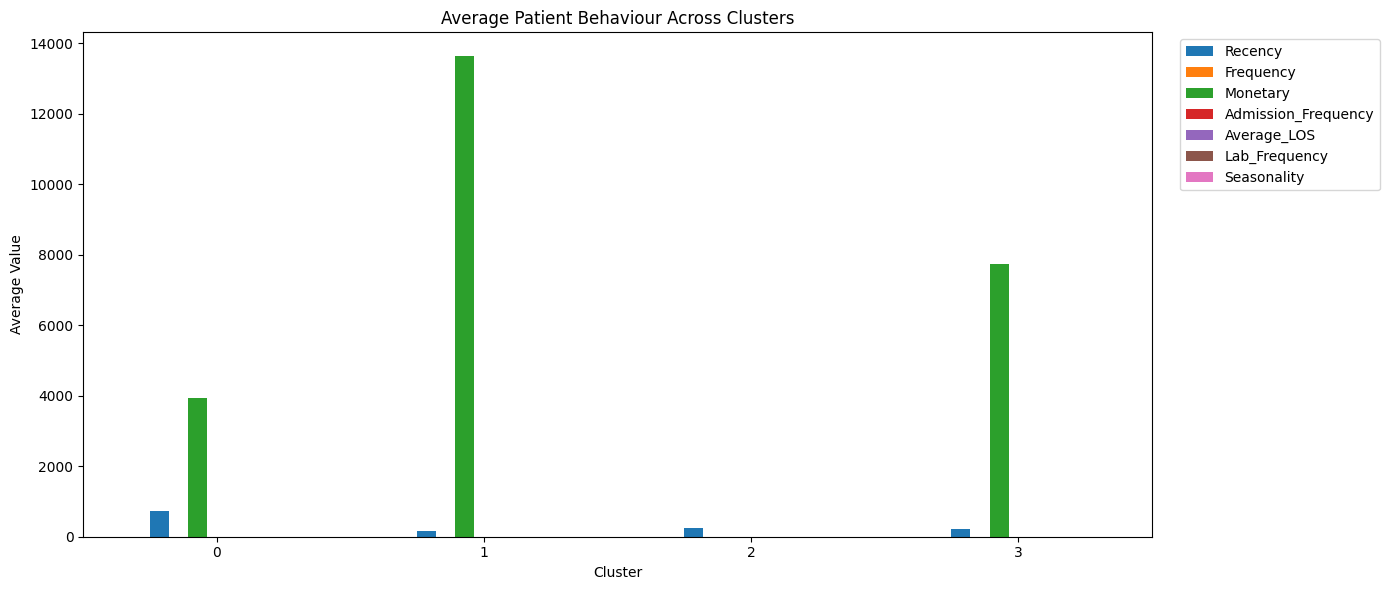

In [7]:
# Visualize average feature values across clusters

cluster_profile.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Average Patient Behaviour Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

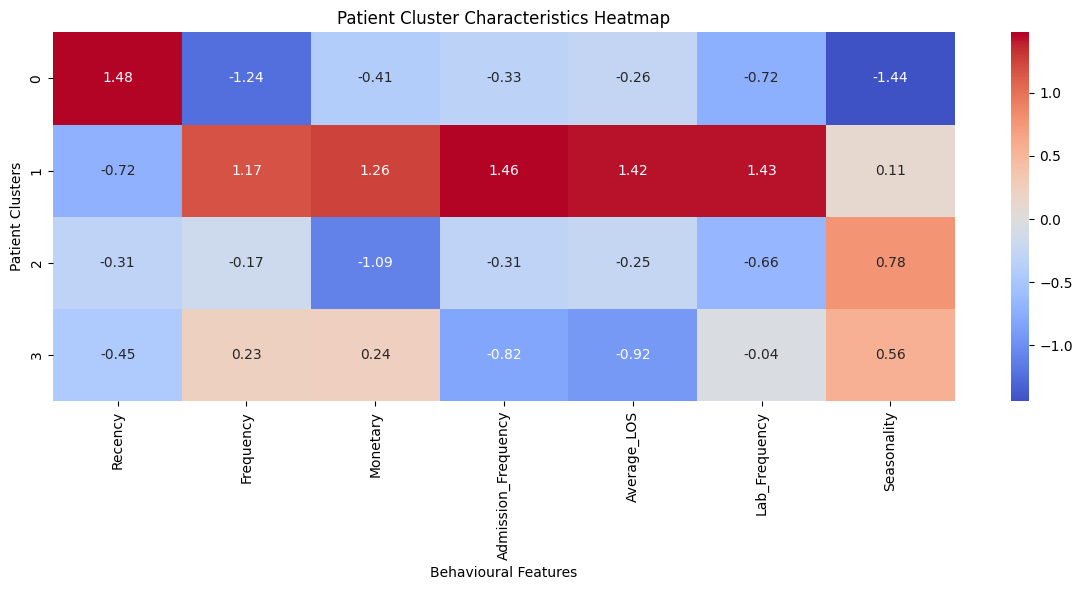

In [8]:
# Create a heatmap of cluster characteristics

import seaborn as sns

# Calculate average values for each cluster
cluster_means = df.groupby("Cluster")[[
    "Recency",
    "Frequency",
    "Monetary",
    "Admission_Frequency",
    "Average_LOS",
    "Lab_Frequency",
    "Seasonality"
]].mean()

# Standardize cluster averages column-wise for visualization
cluster_heatmap = (
    cluster_means - cluster_means.mean()
) / cluster_means.std()

plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_heatmap,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Patient Cluster Characteristics Heatmap")
plt.xlabel("Behavioural Features")
plt.ylabel("Patient Clusters")
plt.tight_layout()
plt.show()

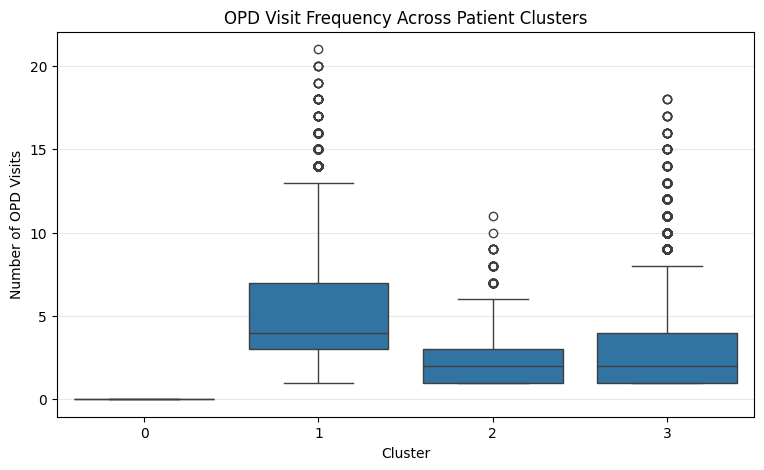

In [9]:
# Compare OPD visit frequency across clusters

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Cluster",
    y="Frequency"
)

plt.title("OPD Visit Frequency Across Patient Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of OPD Visits")
plt.grid(axis="y", alpha=0.3)
plt.show()

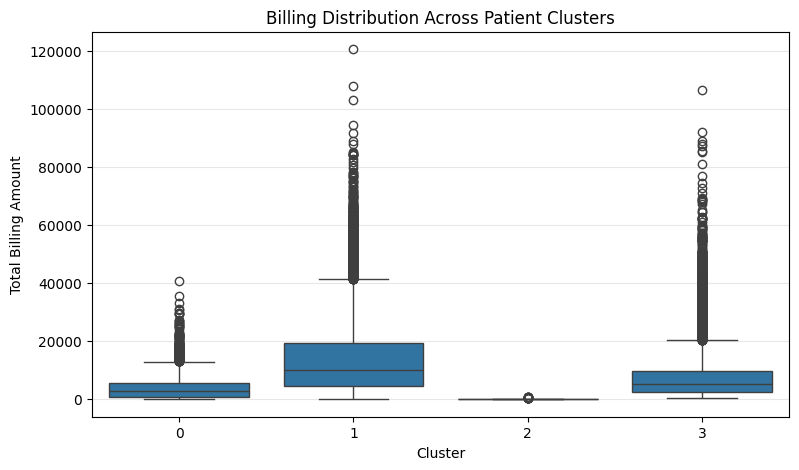

In [10]:
# Compare monetary values across clusters

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Cluster",
    y="Monetary"
)

plt.title("Billing Distribution Across Patient Clusters")
plt.xlabel("Cluster")
plt.ylabel("Total Billing Amount")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [11]:
# Create a comprehensive cluster KPI summary

cluster_kpi = df.groupby("Cluster").agg(
    Patient_Count=("patient_id", "count"),
    Average_Recency=("Recency", "mean"),
    Average_OPD_Visits=("Frequency", "mean"),
    Average_Billing=("Monetary", "mean"),
    Total_Billing=("Monetary", "sum"),
    Average_Admissions=("Admission_Frequency", "mean"),
    Average_LOS=("Average_LOS", "mean"),
    Average_Lab_Tests=("Lab_Frequency", "mean")
).round(2)

# Calculate patient percentage

cluster_kpi["Patient_Percentage"] = (
    cluster_kpi["Patient_Count"] / len(df) * 100
).round(2)

display(cluster_kpi)

,Patient_Count,Average_Recency,Average_OPD_Visits,Average_Billing,Total_Billing,Average_Admissions,Average_LOS,Average_Lab_Tests,Patient_Percentage
Cluster,,,,,,,,,
0,4713,730.00,0.00,3945.74,1.859628e+07,0.40,1.61,1.25,9.43
1,20717,152.74,5.15,13629.26,2.823574e+08,1.69,5.43,3.36,41.43
2,4723,259.87,2.29,2.24,1.056393e+04,0.42,1.63,1.32,9.45
3,19847,223.82,3.15,7724.85,1.533152e+08,0.05,0.11,1.92,39.69


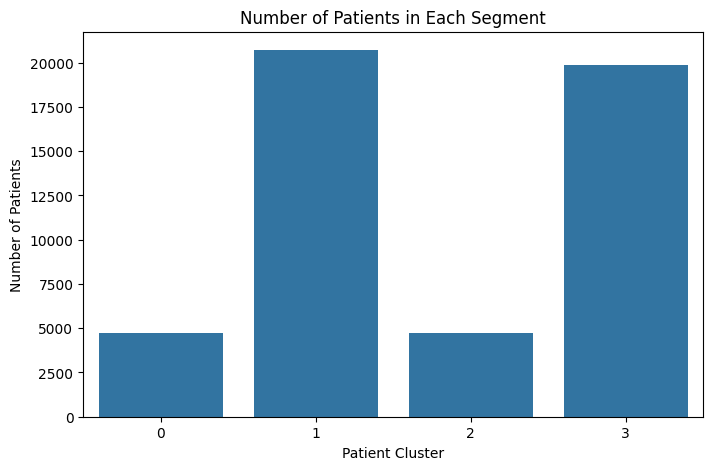

In [12]:
# Plot patient distribution across clusters

plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_kpi.index,
    y=cluster_kpi["Patient_Count"]
)

plt.title("Number of Patients in Each Segment")
plt.xlabel("Patient Cluster")
plt.ylabel("Number of Patients")
plt.show()

In [13]:
# Create business recommendations for each patient segment

recommendations = pd.DataFrame({
    "Cluster": [0, 1, 2, 3],

    "Segment": [
        "No Recent OPD Activity",
        "High Utilization Patients",
        "Low Billing Patients",
        "OPD-Focused Patients"
    ],

    "Recommended_Action": [
        "Send appointment reminders and follow-up messages",
        "Introduce personalized preventive health check-up packages",
        "Review billing records and improve billing data completeness",
        "Promote appropriate preventive health screening services"
    ],

    "Estimated_Cost_Per_Patient": [
        50, 300, 40, 150
    ],

    "Expected_Target": [
        "10% increase in OPD reactivation",
        "10% increase in preventive check-up participation",
        "Improve billing record completeness by 15%",
        "10% increase in screening participation"
    ]
})

display(recommendations)

,Cluster,Segment,Recommended_Action,Estimated_Cost_Per_Patient,Expected_Target
0,0,No Recent OPD Activity,Send appointment reminders and follow-up messages,50,10% increase in OPD reactivation
1,1,High Utilization Patients,Introduce personalized preventive health check...,300,10% increase in preventive check-up participation
2,2,Low Billing Patients,Review billing records and improve billing dat...,40,Improve billing record completeness by 15%
3,3,OPD-Focused Patients,Promote appropriate preventive health screenin...,150,10% increase in screening participation


In [14]:
# Save KPI summary

cluster_kpi.to_csv(
    "../outputs/cluster_kpi_summary.csv"
)

# Save recommendations

recommendations.to_csv(
    "../outputs/cluster_recommendations.csv",
    index=False
)

print("Cluster KPI and recommendation reports saved successfully!")

Cluster KPI and recommendation reports saved successfully!


In [15]:
# Create final patient segmentation summary

final_summary = cluster_kpi.merge(
    recommendations,
    on="Cluster",
    how="left"
)

display(final_summary)

,Cluster,Patient_Count,Average_Recency,Average_OPD_Visits,Average_Billing,Total_Billing,Average_Admissions,Average_LOS,Average_Lab_Tests,Patient_Percentage,Segment,Recommended_Action,Estimated_Cost_Per_Patient,Expected_Target
0,0,4713,730.00,0.00,3945.74,1.859628e+07,0.40,1.61,1.25,9.43,No Recent OPD Activity,Send appointment reminders and follow-up messages,50,10% increase in OPD reactivation
1,1,20717,152.74,5.15,13629.26,2.823574e+08,1.69,5.43,3.36,41.43,High Utilization Patients,Introduce personalized preventive health check...,300,10% increase in preventive check-up participation
2,2,4723,259.87,2.29,2.24,1.056393e+04,0.42,1.63,1.32,9.45,Low Billing Patients,Review billing records and improve billing dat...,40,Improve billing record completeness by 15%
3,3,19847,223.82,3.15,7724.85,1.533152e+08,0.05,0.11,1.92,39.69,OPD-Focused Patients,Promote appropriate preventive health screenin...,150,10% increase in screening participation


In [16]:
# Save final segmentation report

final_summary.to_csv(
    "../outputs/final_patient_segmentation_report.csv",
    index=False
)

print("Final segmentation report saved successfully!")

Final segmentation report saved successfully!


In [17]:
# Validate the final segmentation

print("Total Patients:", len(df))

print("\nNumber of Clusters:", df["Cluster"].nunique())

print("\nCluster Distribution:")
print(df["Cluster"].value_counts().sort_index())

print("\nMinimum Cluster Percentage:",
      round(df["Cluster"].value_counts(normalize=True).min() * 100, 2), "%")

print("\nMissing Cluster Labels:", df["Cluster"].isna().sum())

Total Patients: 50000

Number of Clusters: 4

Cluster Distribution:
Cluster
0     4713
1    20717
2     4723
3    19847
Name: count, dtype: int64

Minimum Cluster Percentage: 9.43 %

Missing Cluster Labels: 0
